# DBSCAN Clustering on Customer Marketing Data

**Dataset:** `marketing_campaign.csv` (2,240 customers of a retail company, 29 columns)
**Goal:** find natural groups of customers with DBSCAN, tune its two parameters properly, and explain what each group (and the "noise") actually means for marketing.

---

### A quick refresher on DBSCAN (in my own words)

Most clustering algorithms (like K-Means) ask *"how many groups do you want?"*. DBSCAN asks a different question: *"where are the crowded areas in the data?"*

It only needs two settings:

| Parameter | What it means |
|---|---|
| **eps (ε)** | The radius of the circle we draw around each point. Two points closer than eps are "neighbours". |
| **min_samples** | How many neighbours (including itself) a point needs inside that circle to count as a *core point*. |

With these two rules every point gets one of three roles:

- **Core point** – sits in a crowded area (has at least `min_samples` neighbours within `eps`).
- **Border point** – not crowded itself, but lies within `eps` of a core point, so it joins that cluster.
- **Noise point** – neither of the above. DBSCAN labels these as `-1` and does not force them into any cluster.

A cluster is simply a chain of core points that can reach each other (this is what "density reachability" means), plus the border points hanging on to them.

**Why it suits customer data:** we don't know the number of segments in advance, segments don't have to be round, and unusual customers get flagged as noise instead of dragging a cluster centre around.

**The catch:** results change a lot with eps and min_samples, and because DBSCAN works on distances, the features *must* be on the same scale. (The assignment brief says DBSCAN is "less sensitive to feature scales" - that's not really true. Income is in the tens of thousands while number of children is 0-3, so without scaling, income would decide everything. I standardise all features below.)

## 1. Setup and Data Loading

In [2]:
# pandas / numpy for handling the table, matplotlib + seaborn for charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn pieces we need
from sklearn.preprocessing import StandardScaler     # puts every feature on the same scale
from sklearn.neighbors import NearestNeighbors       # used for the k-distance graph (to pick eps)
from sklearn.cluster import DBSCAN                   # the clustering algorithm itself
from sklearn.decomposition import PCA                # only used to draw the clusters in 2D
from sklearn.metrics import silhouette_score, davies_bouldin_score

import warnings
warnings.filterwarnings("ignore")                     # keeps the output clean

sns.set_style("whitegrid")                            # simple, readable chart style
pd.set_option("display.max_columns", 40)              # show all columns when printing tables

One thing that tripped me up first: although the file ends in `.csv`, the values are separated by **tabs**, not commas. Reading it with the default settings gives a single giant column. So I pass `sep="\t"`.

In [3]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DBScan_Customer Personality Analysis/marketing_campaign.csv', sep="\t")   #Tab Seprated File (sep="\t")

In [4]:
df.shape

(2240, 29)

In [5]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


## 2. First Look at the Data

In [6]:
# data types and how many non-empty values each column has
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [7]:
df.isnull().sum()

,0
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


In [8]:
# count missing values per column (only show columns that actually have some)
missing = df.isnull().sum()
print(missing[missing > 0])

Income    24
dtype: int64


In [9]:
# basic statistics - transpose (.T) so it is easier to read
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.16,3246.66,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.81,11.98,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.25,25173.08,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.44,0.54,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.51,0.54,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.94,336.60,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.30,39.77,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.95,225.72,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.53,54.63,0.0,3.00,12.0,50.00,259.0


**What I notice in the raw numbers:**
- `Year_Birth` has a minimum of **1893** - a customer aged over 120. That's a data entry error.
- `Income` has a maximum of **666,666** while the 75th percentile is about 68,500. That looks like a placeholder value, not a real income.
- All spending columns have a mean much higher than the median (e.g. wine: mean 304, median 173.5). So spending is **right-skewed**: most people spend little, a few spend a lot.
- `Z_CostContact` (always 3) and `Z_Revenue` (always 11) never change, so they are useless for clustering.
- Only `Income` has missing values (24 rows).

In [10]:
# the two text columns - what values do they contain?
print(df["Education"].value_counts(), "\n")
print(df["Marital_Status"].value_counts())

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64 

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


`Marital_Status` contains some joke entries (**"Absurd"**, **"YOLO"**) and "Alone" which is basically "Single". For describing clusters later I merge everything into two groups: *Partner* (Married / Together) and *Alone* (all the rest). Education is merged into three levels. These two text columns are **not** used in the clustering itself - only for describing the clusters afterwards.

## 3. Data Cleaning

In [11]:
# 1) drop the rows where income is missing (only 24 out of 2240, about 1%)
df = df.dropna(subset=["Income"])

In [12]:
df.isnull().sum()

,0
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,0
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


In [13]:
# 2) Z_CostContact and Z_Revenue have the same value in every row -> no information, drop them
df = df.drop(columns=["Z_CostContact", "Z_Revenue"])

In [14]:
# 3) turn the joining date into a real date (format in this file is day-month-year)
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
print("Customers joined between", df["Dt_Customer"].min().date(), "and", df["Dt_Customer"].max().date())

print("Rows left:", len(df))

Customers joined between 2012-07-30 and 2014-06-29
Rows left: 2216


In [15]:
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,2013-06-13,46,709,43,182,42,118,247,2,9,3,4,5,0,0,0,0,0,0,0
2236,4001,1946,PhD,Together,64014.0,2,1,2014-06-10,56,406,0,30,0,0,8,7,8,2,5,7,0,0,0,1,0,0,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,2014-01-25,91,908,48,217,32,12,24,1,2,3,13,6,0,1,0,0,0,0,0
2238,8235,1956,Master,Together,69245.0,0,1,2014-01-24,8,428,30,214,80,30,61,2,6,5,10,3,0,0,0,0,0,0,0


### Feature engineering

The raw columns are quite split up (6 separate spending columns, 3 purchase-channel columns, kids and teens separately). I combine them into a few columns that are easier to reason about.

For **Age** I use 2014 as the reference year, because the most recent customer joined in mid-2014 - the data was collected around then, so ages are calculated relative to that and not to today.

In [16]:
df["Age"] = 2014 - df["Year_Birth"]

# total money spent across all 6 product categories over the last 2 years
spend_cols = ["MntWines", "MntFruits", "MntMeatProducts",
              "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df["Total_Spent"] = df[spend_cols].sum(axis=1)

# kids + teenagers living at home
df["Children"] = df["Kidhome"] + df["Teenhome"]

# purchases made through web, catalogue and store (deals are counted separately)
df["Total_Purchases"] = df["NumWebPurchases"] + df["NumCatalogPurchases"] + df["NumStorePurchases"]

# how many of the 5 earlier campaigns the customer accepted
cmp_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]
df["Total_Accepted"] = df[cmp_cols].sum(axis=1)

# simplify categories (only used for describing the groups, not for clustering)
df["Marital_Status"] = df["Marital_Status"].replace({"Married": "Partner", "Together": "Partner",
                                                     "Single": "Alone", "Divorced": "Alone",
                                                     "Widow": "Alone", "Absurd": "Alone", "YOLO": "Alone"})
df["Education"] = df["Education"].replace({"Basic": "Undergraduate", "2n Cycle": "Undergraduate",
                                           "Graduation": "Graduate",
                                           "Master": "Postgraduate", "PhD": "Postgraduate"})

df[["Age", "Income", "Total_Spent", "Children", "Total_Purchases", "Total_Accepted"]].describe().round(1)

,Age,Income,Total_Spent,Children,Total_Purchases,Total_Accepted
count,2216.0,2216.0,2216.0,2216.0,2216.0,2216.0
mean,45.2,52247.3,607.1,0.9,12.6,0.3
std,12.0,25173.1,602.9,0.7,7.2,0.7
min,18.0,1730.0,5.0,0.0,0.0,0.0
25%,37.0,35303.0,69.0,0.0,6.0,0.0
50%,44.0,51381.5,396.5,1.0,12.0,0.0
75%,55.0,68522.0,1048.0,1.0,18.0,0.0
max,121.0,666666.0,2525.0,3.0,32.0,4.0


`Age` has a max of **121** and `Income` a max of **666,666**, confirming what I spotted earlier. Let's look at them before deciding what to remove.

### Checking the suspicious values with boxplots

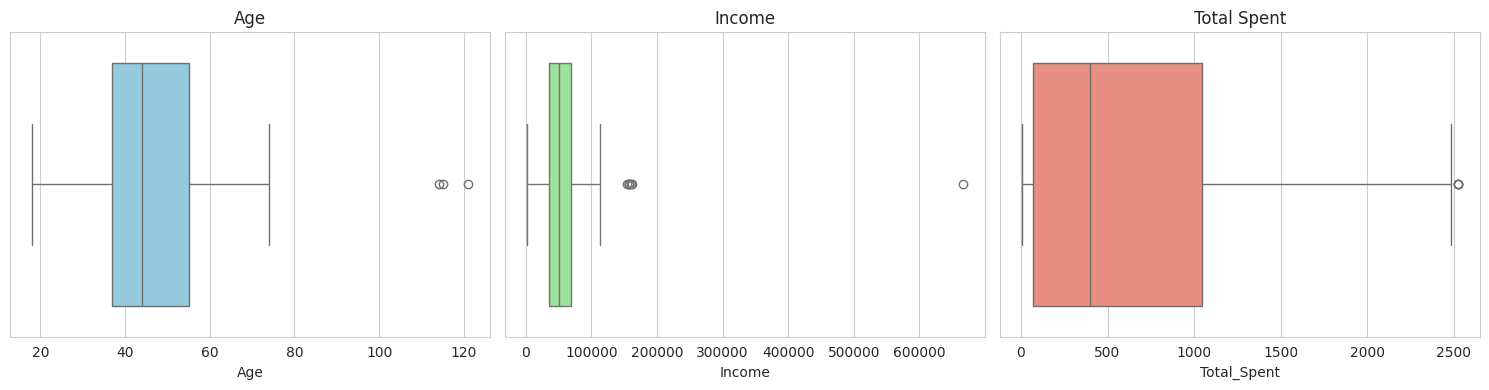

        ID  Year_Birth  Age   Income
192   7829        1900  114  36640.0
239  11004        1893  121  60182.0
339   1150        1899  115  83532.0
        ID    Income  Total_Spent
2233  9432  666666.0           62


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x=df["Age"], ax=axes[0], color="skyblue")
axes[0].set_title("Age")

sns.boxplot(x=df["Income"], ax=axes[1], color="lightgreen")
axes[1].set_title("Income")

sns.boxplot(x=df["Total_Spent"], ax=axes[2], color="salmon")
axes[2].set_title("Total Spent")

plt.tight_layout()
plt.show()

# print the exact rows behind the extreme points
print(df.loc[df["Age"] > 90, ["ID", "Year_Birth", "Age", "Income"]])
print(df.loc[df["Income"] > 200000, ["ID", "Income", "Total_Spent"]])

- Three customers were "born" in 1893, 1899 and 1900 - clearly typing mistakes.
- One customer has an income of 666,666 but spent only 62 in two years - not believable.

Only these 4 rows are removed. I'm **not** removing the other high spenders or high earners shown as dots in the boxplots; they are real customers, and deciding what is "unusual" is exactly what DBSCAN's noise label is for.

In [18]:
before = len(df)
df = df[(df["Age"] <= 90) & (df["Income"] < 200000)]   # keep realistic ages and incomes
df = df.reset_index(drop=True)                            # clean 0..n-1 index after filtering
print("Removed", before - len(df), "rows ->", len(df), "customers left for analysis")

Removed 4 rows -> 2212 customers left for analysis


## 4. Exploratory Data Analysis

### 4.1 Distributions of the main numeric features

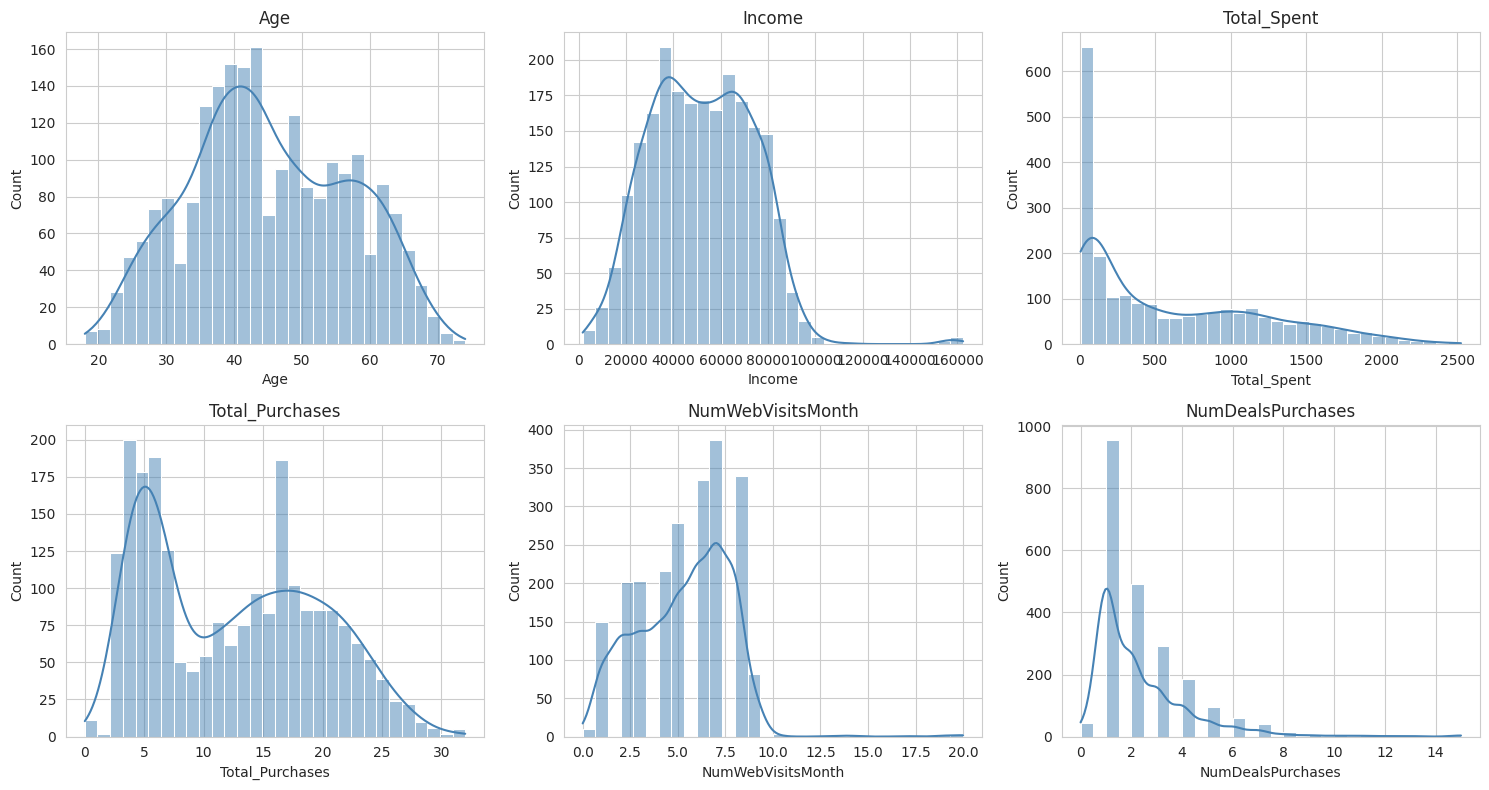

In [19]:
cols = ["Age", "Income", "Total_Spent", "Total_Purchases", "NumWebVisitsMonth", "NumDealsPurchases"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), cols):          # one small chart per column
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

- **Income** is roughly bell-shaped, centred around 50k.
- **Total_Spent** is strongly right-skewed: lots of customers below 100, then a long tail up to about 2,500.
- **NumDealsPurchases** is mostly 1-3, with a handful of customers at 10-15. Those are likely to end up as noise.
- **NumWebVisitsMonth** mostly lies between 2 and 9, with a few values up to 20.

### 4.2 Household and demographic breakdown

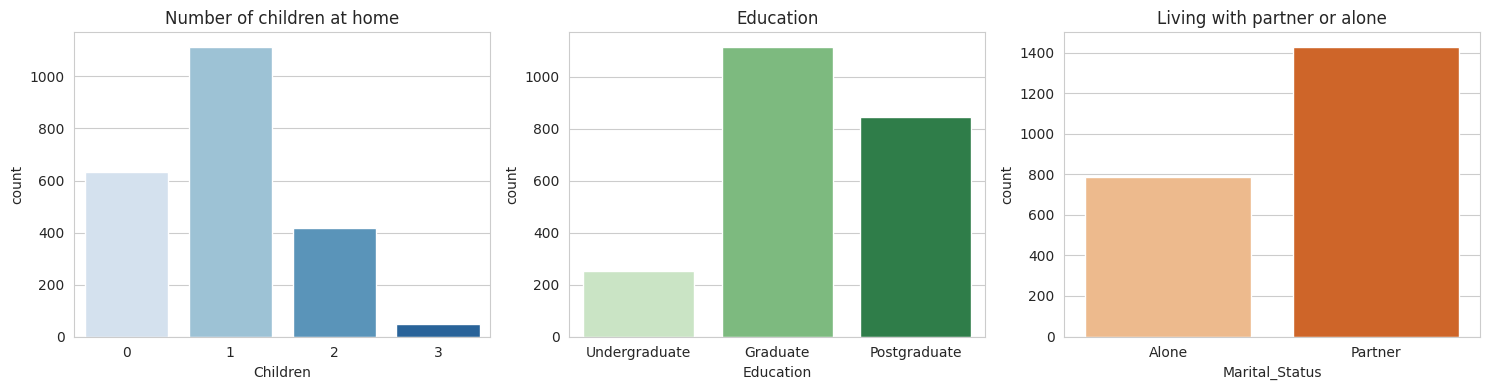

Children
0     632
1    1114
2     416
3      50
Name: count, dtype: int64


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(x="Children", data=df, ax=axes[0], palette="Blues")
axes[0].set_title("Number of children at home")

sns.countplot(x="Education", data=df, ax=axes[1], palette="Greens",
              order=["Undergraduate", "Graduate", "Postgraduate"])
axes[1].set_title("Education")

sns.countplot(x="Marital_Status", data=df, ax=axes[2], palette="Oranges")
axes[2].set_title("Living with partner or alone")

plt.tight_layout()
plt.show()

print(df["Children"].value_counts().sort_index())

### 4.3 How does spending change with income and children?

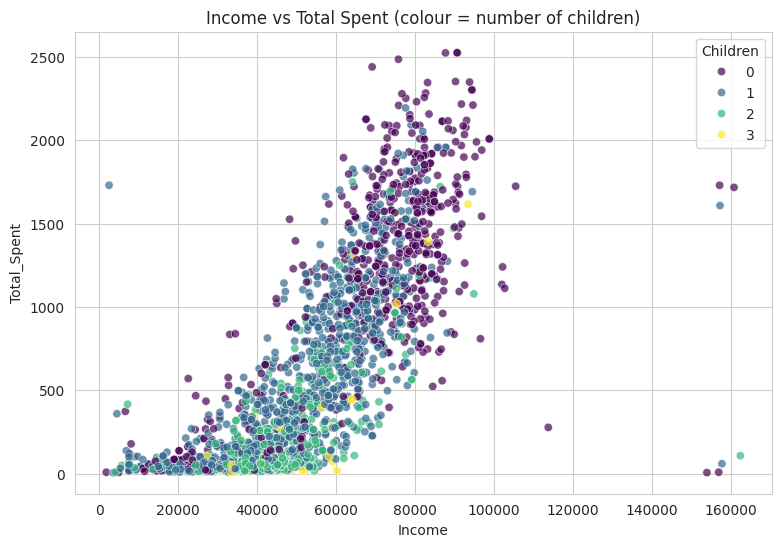

In [21]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x="Income", y="Total_Spent", hue="Children", data=df,
                palette="viridis", alpha=0.7)
plt.title("Income vs Total Spent (colour = number of children)")
plt.show()

In [22]:
# average spending for each number of children
df.groupby("Children")[["Income", "Total_Spent", "Total_Purchases", "NumDealsPurchases"]].mean().round(0)

,Income,Total_Spent,Total_Purchases,NumDealsPurchases
Children,,,,
0,65677.0,1104.0,16.0,1.0
1,47156.0,476.0,12.0,2.0
2,44612.0,247.0,9.0,4.0
3,46677.0,256.0,8.0,4.0


This is the most useful chart so far. Customers without children form a clear high-income, high-spending band (average spend 1,104), while each extra child pulls spending down (476 with one child, 247 with two) and pushes deal purchases up (from 1 to 4 on average). So I already expect household size to be one of the things that separates groups.

#4.4 Correlation heatmap

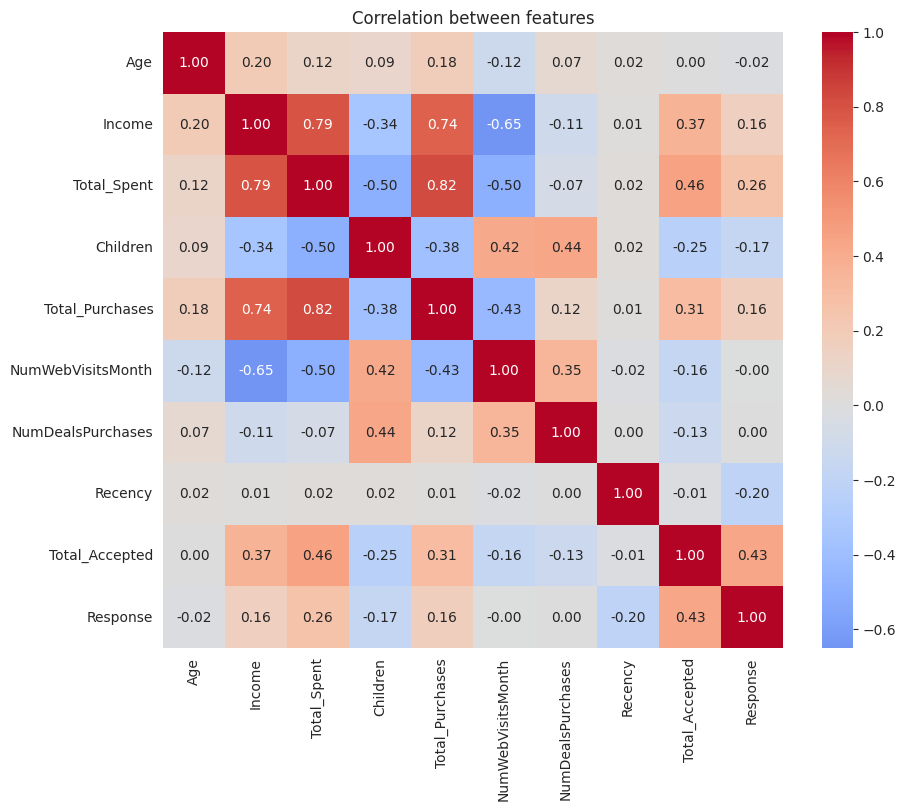

In [23]:
corr_cols = ["Age", "Income", "Total_Spent", "Children", "Total_Purchases",
             "NumWebVisitsMonth", "NumDealsPurchases", "Recency", "Total_Accepted", "Response"]

plt.figure(figsize=(10, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between features")
plt.show()

Main relationships (values from the heatmap):

Income and Total_Spent are strongly linked (0.79), and Total_Spent with Total_Purchases even more (0.82).
Children is negatively linked with spending (-0.50) and positively with deal purchases (0.44) and web visits (0.42).
Higher income -> fewer web visits (-0.65). Better-off customers browse the website less.
Accepting earlier campaigns goes together with responding to the last one (0.43), and both rise with spending.
Age and Recency hardly relate to anything else.

#5. Preprocessing - Choosing and Scaling Features

**Which features go into DBSCAN?**

I picked 7 features that describe *who the customer is* and *how they shop*:

`Income, Total_Spent, Total_Purchases, NumWebVisitsMonth, NumDealsPurchases, Children, Age`

What I deliberately left out:

- **0/1 campaign columns** (`AcceptedCmp1-5`, `Response`, `Complain`) - binary columns pile lots of customers onto exactly the same value, which creates fake "density" that DBSCAN would latch onto. I keep them aside and use them *after* clustering to check whether the groups respond differently to marketing. That's a fairer test of whether the clusters are meaningful.

- **Recency** - it is spread almost evenly from 0 to 99 days and has practically zero correlation with the other customer features (the only link is a weak -0.20 with `Response`). An evenly spread feature has no dense areas, so it only blurs the distances.

- **The 6 separate spend columns** - already summarised by `Total_Spent`. Using all of them would give spending 6 times the weight of the other features.

I keep the feature count low on purpose: in high dimensions every point starts looking far away from every other point, and density-based methods struggle.

In [24]:
features = ["Income", "Total_Spent", "Total_Purchases", "NumWebVisitsMonth",
            "NumDealsPurchases", "Children", "Age"]

X = df[features]

# StandardScaler: (value - mean) / standard deviation  ->  every column gets mean 0, std 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# quick check that scaling worked
pd.DataFrame(X_scaled, columns=features).describe().loc[["mean", "std"]].round(2)

,Income,Total_Spent,Total_Purchases,NumWebVisitsMonth,NumDealsPurchases,Children,Age
mean,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 6. Choosing DBSCAN Parameters

### 6.1 min_samples

A common rule of thumb is `min_samples = 2 x number of features`. With 7 features that gives **14**. A bigger value makes the algorithm stricter (smaller, denser clusters and more noise). I'll start from 14 and still test other values in the grid search below.

### 6.2 eps - the k-distance graph

For every customer I measure the distance to its 14th nearest neighbour, sort these distances, and plot them. Points in crowded areas have small values; isolated points have large values. The "elbow" (where the curve suddenly shoots up) is the usual suggestion for eps.

To avoid eyeballing the elbow I find it with a simple trick: normalise both axes to 0-1 and take the point that is furthest below the straight line joining the first and last point.

Elbow at point 2129 -> suggested eps = 1.61


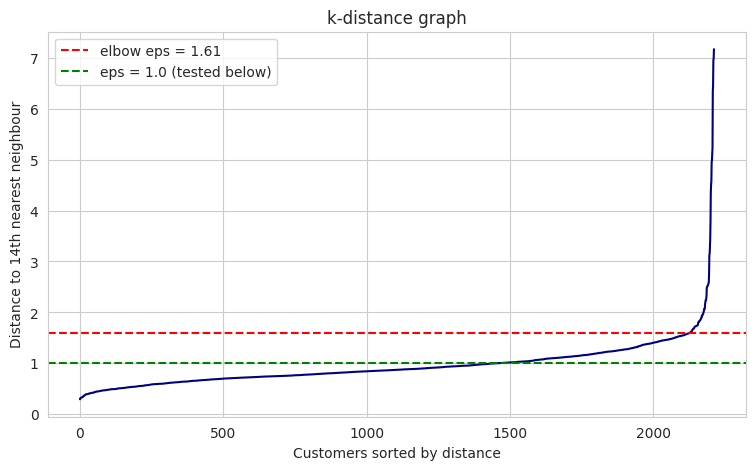

In [25]:
k = 14

# distance from each point to its k-th neighbour (the point itself counts as the 1st)
nn = NearestNeighbors(n_neighbors=k).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])            # take the last column (k-th neighbour) and sort

# find the elbow: largest gap between the diagonal line and the curve (both scaled 0-1)
x_norm = np.arange(len(k_dist)) / (len(k_dist) - 1)
y_norm = (k_dist - k_dist.min()) / (k_dist.max() - k_dist.min())
elbow_idx = np.argmax(x_norm - y_norm)
elbow_eps = k_dist[elbow_idx]
print(f"Elbow at point {elbow_idx} -> suggested eps = {elbow_eps:.2f}")

plt.figure(figsize=(9, 5))
plt.plot(k_dist, color="navy")
plt.axhline(elbow_eps, color="red", linestyle="--", label=f"elbow eps = {elbow_eps:.2f}")
plt.axhline(1.0, color="green", linestyle="--", label="eps = 1.0 (tested below)")
plt.xlabel("Customers sorted by distance")
plt.ylabel(f"Distance to {k}th nearest neighbour")
plt.title("k-distance graph")
plt.legend()
plt.show()

In [26]:
# what does the elbow value actually give us?
test = DBSCAN(eps=round(elbow_eps, 2), min_samples=14).fit_predict(X_scaled)
print("Clusters:", len(set(test)) - (1 if -1 in test else 0))
print("Noise points:", (test == -1).sum())

Clusters: 1
Noise points: 33


**Interesting result:** the elbow suggests eps ≈ **1.61**, but with that value DBSCAN puts almost everyone (all but 33 customers) into **one big cluster**.

This actually makes sense. The k-distance elbow tells us where the *sparse outskirts* begin, so it's a good value for separating outliers from everything else. But this dataset doesn't contain well-separated islands of customers; it's more like one big continuous cloud with denser and thinner areas inside it. To see the internal structure we need a **smaller eps** than the elbow. So instead of trusting the elbow blindly, I test a range of values.

### 6.3 Grid search over eps and min_samples

For each combination I record:
- number of clusters (noise not counted),
- percentage of customers marked as noise,
- silhouette score, calculated **only on clustered points** (noise is not a real cluster, so including it would be misleading).

Silhouette ranges from -1 to 1: higher means points are closer to their own cluster than to other clusters.

In [27]:
results = []

for ms in [5, 10, 14, 20]:
    for eps in np.arange(0.5, 1.75, 0.1):
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct = (labels == -1).mean() * 100

        # silhouette needs at least 2 clusters
        if n_clusters >= 2:
            mask = labels != -1
            sil = silhouette_score(X_scaled[mask], labels[mask])
        else:
            sil = np.nan

        results.append({"min_samples": ms, "eps": round(eps, 1),
                        "clusters": n_clusters, "noise_%": round(noise_pct, 1),
                        "silhouette": round(sil, 3)})

grid = pd.DataFrame(results)
grid[grid["min_samples"] == 14]

,min_samples,eps,clusters,noise_%,silhouette
26,14,0.5,3,88.7,0.188
27,14,0.6,5,77.5,0.344
28,14,0.7,7,58.7,0.206
29,14,0.8,5,36.5,0.193
30,14,0.9,5,23.3,0.155
31,14,1.0,4,16.5,0.172
32,14,1.1,5,10.8,0.128
33,14,1.2,5,6.7,0.121
34,14,1.3,4,3.8,0.102
35,14,1.4,1,2.4,NaN


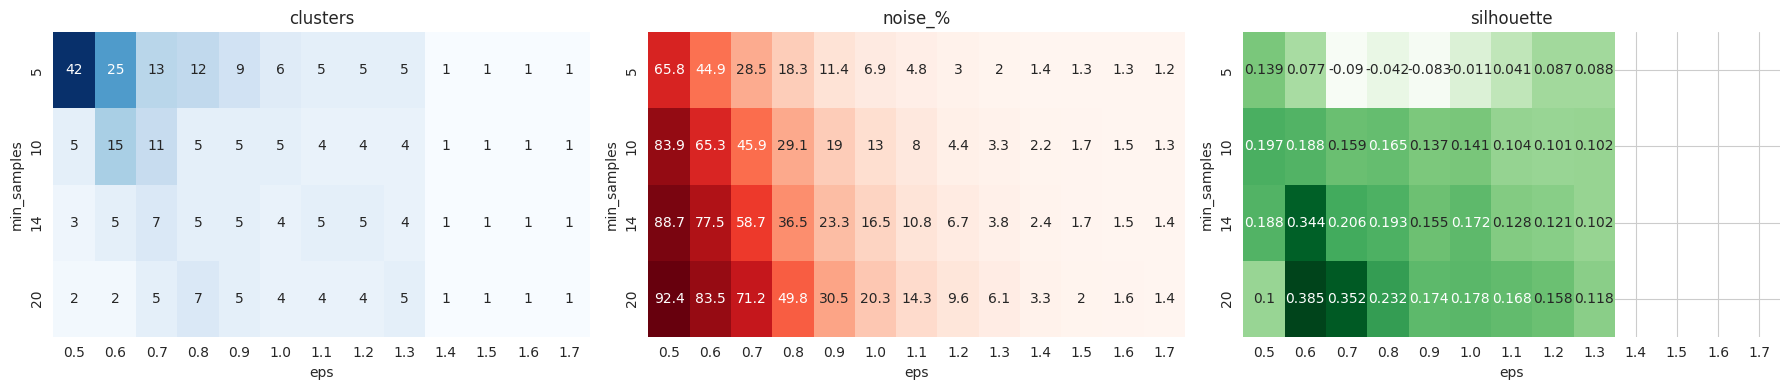

In [28]:
# the same results for all min_samples as heatmaps - easier to compare
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, col, cmap in zip(axes, ["clusters", "noise_%", "silhouette"], ["Blues", "Reds", "Greens"]):
    table = grid.pivot(index="min_samples", columns="eps", values=col)
    sns.heatmap(table, annot=True, fmt=".3g", cmap=cmap, ax=ax, cbar=False)
    ax.set_title(col)

plt.tight_layout()
plt.show()

**Reading the heatmaps:**
- Small eps (0.5-0.7) gives the highest silhouette values (up to 0.385) **but** labels 60-90% of customers as noise. A segmentation that ignores most customers is useless for a marketing team.
- From eps 1.4 upwards, every setting collapses into a single cluster.
- In between, the number of clusters is quite stable at **4-5**, which suggests that structure is real and not a fluke of one parameter value.
- `min_samples = 5` gives negative silhouette values at some eps settings: with such a low threshold, clusters leak into each other.

So I can't simply pick "the highest silhouette". My rule: **at least 3 clusters, at most 20% noise**, and among those, the best silhouette.

In [29]:
# apply my selection rule: at least 3 clusters and at most 20% noise, then sort by silhouette
usable = grid[(grid["clusters"] >= 3) & (grid["noise_%"] <= 20)]
usable.sort_values("silhouette", ascending=False).head(6)

,min_samples,eps,clusters,noise_%,silhouette
31,14,1.0,4,16.5,0.172
45,20,1.1,4,14.3,0.168
46,20,1.2,4,9.6,0.158
18,10,1.0,5,13.0,0.141
17,10,0.9,5,19.0,0.137
32,14,1.1,5,10.8,0.128


The best setting that meets the rule is **eps = 1.0, min_samples = 14** - which is also the value suggested by the 2 × features rule of thumb. It gives 4 clusters, 16.5% noise and a silhouette of 0.172.

## 7. Final DBSCAN Model

In [30]:
dbscan = DBSCAN(eps=1.0, min_samples=14)
labels = dbscan.fit_predict(X_scaled)

df["Cluster"] = labels      # attach the result to the original (unscaled) data

print("Customers per cluster (-1 = noise):")
print(df["Cluster"].value_counts().sort_index())

Customers per cluster (-1 = noise):
Cluster
-1     365
 0     334
 1    1013
 2     406
 3      94
Name: count, dtype: int64


## 8. Evaluating the Clustering

In [31]:
mask = labels != -1        # only clustered points

sil = silhouette_score(X_scaled[mask], labels[mask])
dbi = davies_bouldin_score(X_scaled[mask], labels[mask])

print(f"Silhouette score (noise excluded): {sil:.3f}   (higher is better, max 1)")
print(f"Davies-Bouldin index (noise excluded): {dbi:.3f}   (lower is better, min 0)")

Silhouette score (noise excluded): 0.172   (higher is better, max 1)
Davies-Bouldin index (noise excluded): 1.654   (lower is better, min 0)


In [32]:
# density reachability: how many points are core, border or noise?
core_mask = np.zeros(len(labels), dtype=bool)
core_mask[dbscan.core_sample_indices_] = True          # sklearn gives us the indices of core points

n_core = core_mask.sum()
n_noise = (labels == -1).sum()
n_border = len(labels) - n_core - n_noise              # whatever is left is a border point

summary = pd.DataFrame({"Point type": ["Core", "Border", "Noise"],
                        "Count": [n_core, n_border, n_noise]})
summary["Percent"] = (summary["Count"] / len(labels) * 100).round(1)
print(summary.to_string(index=False))

# same thing broken down per cluster
point_type = np.where(core_mask, "Core", np.where(labels == -1, "Noise", "Border"))
pd.crosstab(df["Cluster"], point_type)

Point type  Count  Percent
      Core   1451     65.6
    Border    396     17.9
     Noise    365     16.5


col_0,Border,Core,Noise
Cluster,,,
-1,0,0,365
0,73,261,0
1,189,824,0
2,96,310,0
3,38,56,0


**How good is this clustering?**

- **Silhouette 0.172** - positive, so points are on average closer to their own cluster, but the clusters are not far apart. That matches what the k-distance graph told us: customer data is a continuum, not separate islands. For real-world customer data a score like this is common; values like 0.7 usually appear only with clearly separated data.

- **Davies-Bouldin 1.65** - moderate overlap between clusters, same message.

- **Density reachability:** 65.6% of customers are *core points* (they sit in properly dense areas), 17.9% are *border points* and 16.5% are noise. Every cluster has a solid core (the smallest one, cluster 3, still has 56 core points), so none of the clusters is just a thin chain of points.

## 9. Visualising the Clusters


We have 7 dimensions, so to draw the result I squash it down to 2 with PCA. PCA is only used for the picture - DBSCAN ran on all 7 scaled features. Some overlap in the 2D picture is expected because information is lost when we flatten 7 dimensions into 2.

Variance explained by the 2 components: [0.479 0.203] -> total 0.682


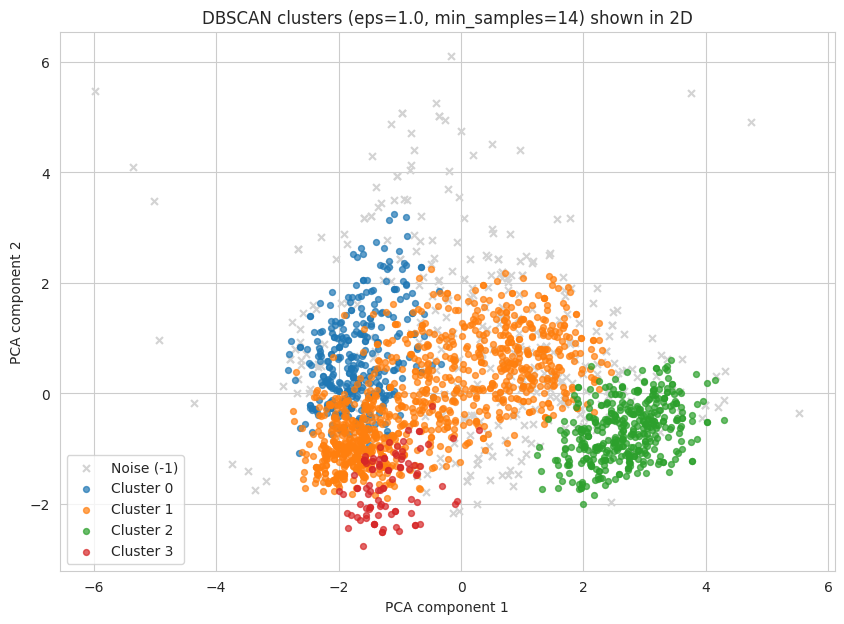

In [33]:
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)
print("Variance explained by the 2 components:", pca.explained_variance_ratio_.round(3),
      "-> total", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(10, 7))

# draw noise first in grey so the clusters appear on top
noise = labels == -1
plt.scatter(X_2d[noise, 0], X_2d[noise, 1], c="lightgrey", marker="x", s=25, label="Noise (-1)")

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]
for c in sorted(set(labels) - {-1}):
    pts = labels == c
    plt.scatter(X_2d[pts, 0], X_2d[pts, 1], s=18, alpha=0.7, color=colors[c], label=f"Cluster {c}")

plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("DBSCAN clusters (eps=1.0, min_samples=14) shown in 2D")
plt.legend()
plt.show()

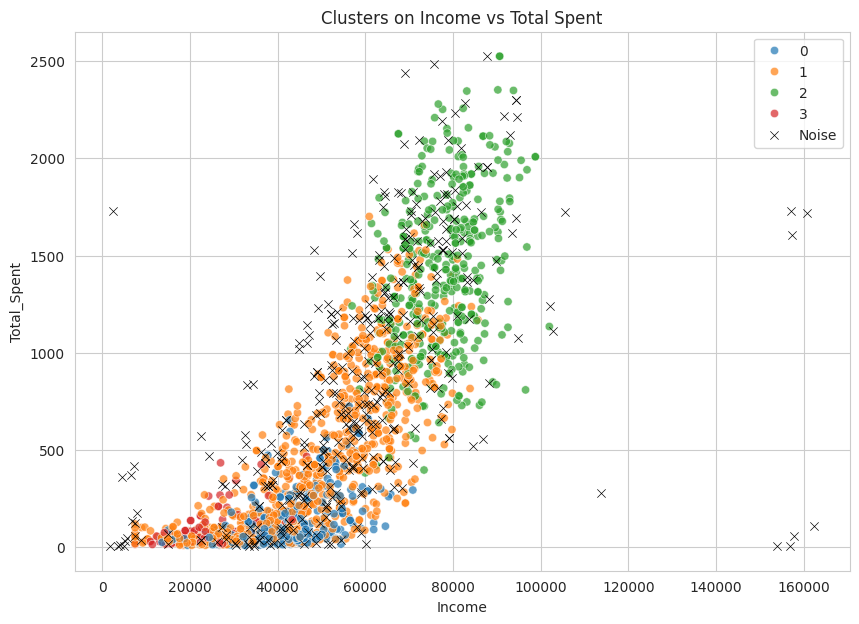

In [34]:
# same clusters on the two most business-relevant original features
plt.figure(figsize=(10, 7))
sns.scatterplot(x="Income", y="Total_Spent", hue="Cluster", data=df[df["Cluster"] != -1],
                palette="tab10", alpha=0.7)
sns.scatterplot(x="Income", y="Total_Spent", data=df[df["Cluster"] == -1],
                color="black", marker="x", label="Noise")
plt.title("Clusters on Income vs Total Spent")
plt.show()

## 10. Cluster Analysis - What Defines Each Group?

In [35]:
profile_cols = features + ["Recency", "Total_Accepted", "Response", "Complain"]

profile = df.groupby("Cluster")[profile_cols].mean().round(2)
profile["Size"] = df["Cluster"].value_counts()
profile["Size_%"] = (profile["Size"] / len(df) * 100).round(1)
profile

,Income,Total_Spent,Total_Purchases,NumWebVisitsMonth,NumDealsPurchases,Children,Age,Recency,Total_Accepted,Response,Complain,Size,Size_%
Cluster,,,,,,,,,,,,,
-1,59270.07,864.77,16.15,5.98,3.44,1.14,48.95,50.00,0.47,0.21,0.01,365,16.5
0,40721.13,129.65,6.72,6.33,3.05,2.00,48.01,49.04,0.11,0.11,0.01,334,15.1
1,45346.08,400.76,11.35,5.92,2.34,1.00,43.16,48.66,0.15,0.09,0.01,1013,45.8
2,77399.07,1401.09,18.79,2.14,0.98,0.00,45.06,49.67,0.71,0.29,0.00,406,18.4
3,24881.43,101.33,5.66,6.53,1.12,0.00,40.60,46.23,0.11,0.10,0.01,94,4.2


In [36]:
# number of children inside each cluster - is it mixed or pure?
pd.crosstab(df["Cluster"], df["Children"])

Children,0,1,2,3
Cluster,,,,
-1,132,101,82,50
0,0,0,334,0
1,0,1013,0,0
2,406,0,0,0
3,94,0,0,0


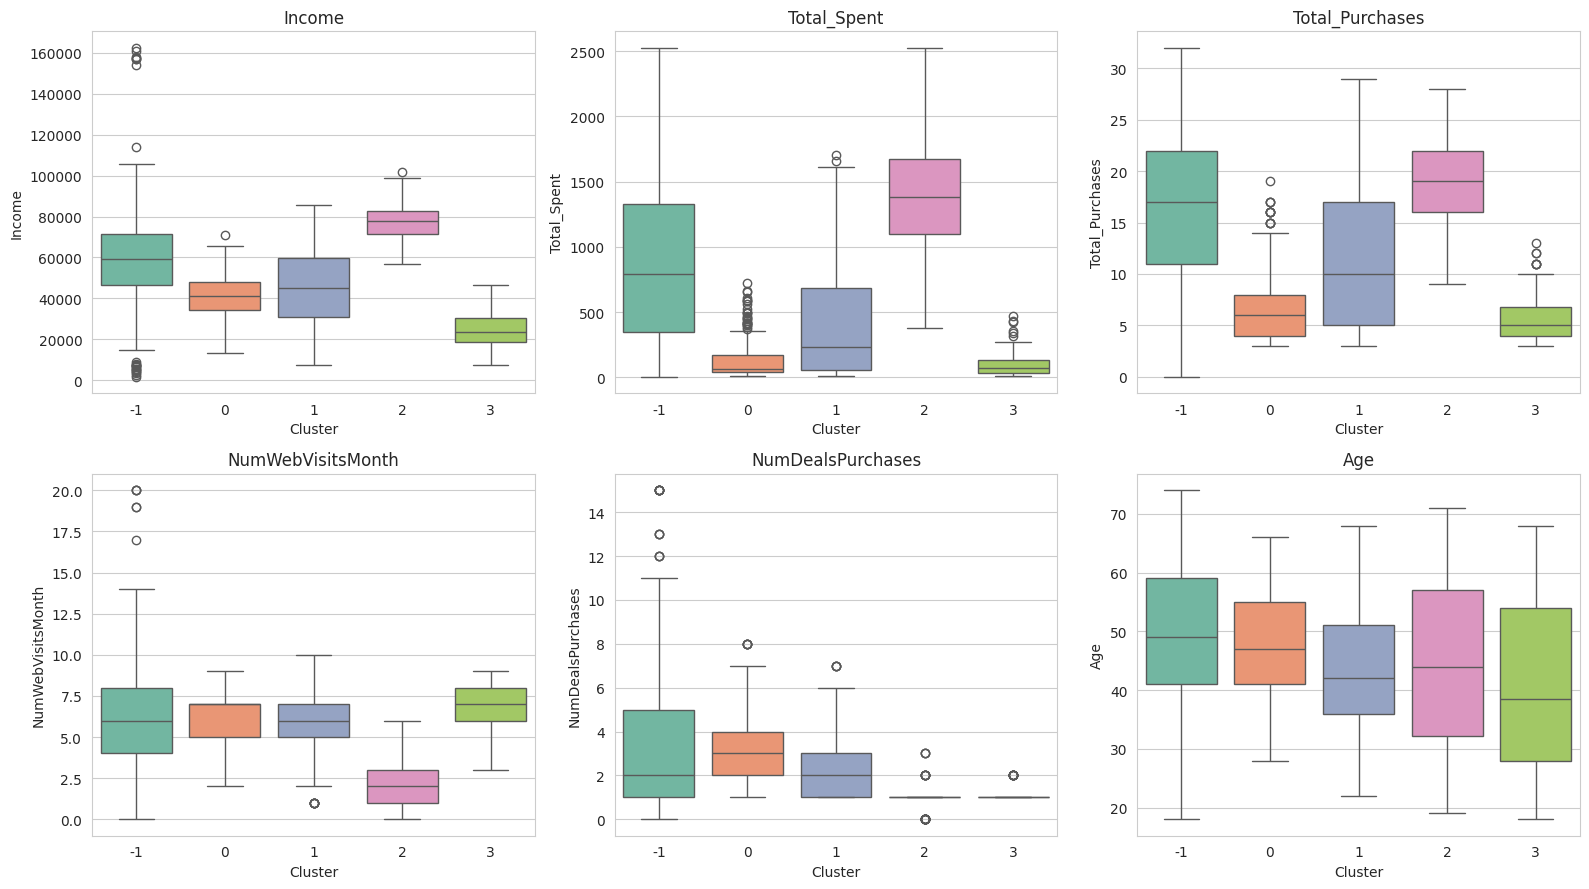

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
box_cols = ["Income", "Total_Spent", "Total_Purchases", "NumWebVisitsMonth", "NumDealsPurchases", "Age"]

for ax, col in zip(axes.flatten(), box_cols):
    sns.boxplot(x="Cluster", y=col, data=df, ax=ax, palette="Set2")
    ax.set_title(col)

plt.tight_layout()
plt.show()

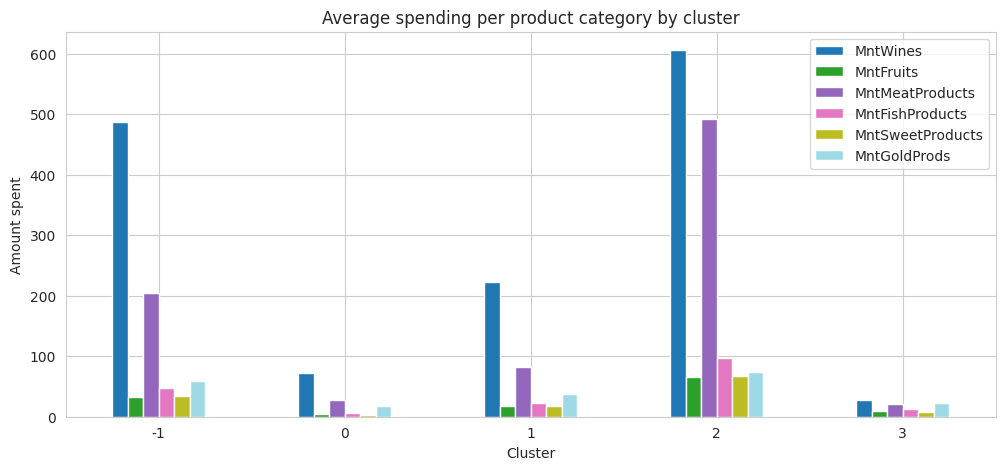

,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds
Cluster,,,,,,
-1,487.0,32.0,205.0,47.0,35.0,59.0
0,72.0,4.0,27.0,6.0,3.0,18.0
1,222.0,17.0,83.0,23.0,18.0,37.0
2,606.0,66.0,492.0,97.0,67.0,74.0
3,27.0,9.0,21.0,13.0,8.0,23.0


In [38]:
# where does each cluster spend its money? (average amount per product)
spend_profile = df.groupby("Cluster")[spend_cols].mean().round(0)
spend_profile.plot(kind="bar", figsize=(12, 5), colormap="tab20")
plt.title("Average spending per product category by cluster")
plt.ylabel("Amount spent")
plt.xticks(rotation=0)
plt.show()
spend_profile

In [39]:
# campaign response rate per cluster (in %), plus education/marital mix
resp = (df.groupby("Cluster")[cmp_cols + ["Response"]].mean() * 100).round(1)
resp

,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Response
Cluster,,,,,,
-1,11.0,3.6,7.9,13.7,11.2,20.5
0,0.6,0.6,7.8,2.4,0.0,11.1
1,1.1,0.5,7.0,5.7,0.5,9.4
2,21.7,2.5,7.4,11.3,28.3,28.8
3,1.1,0.0,7.4,2.1,0.0,9.6


In [40]:
print((pd.crosstab(df["Cluster"], df["Education"], normalize="index") * 100).round(1), "\n")
print((pd.crosstab(df["Cluster"], df["Marital_Status"], normalize="index") * 100).round(1))

Education  Graduate  Postgraduate  Undergraduate
Cluster                                         
-1             48.2          44.1            7.7
 0             48.2          42.2            9.6
 1             51.5          36.3           12.1
 2             52.0          39.2            8.9
 3             47.9          17.0           35.1 

Marital_Status  Alone  Partner
Cluster                       
-1               35.9     64.1
 0               34.7     65.3
 1               33.9     66.1
 2               39.7     60.3
 3               35.1     64.9


### What the clusters are

The crosstab with `Children` shows something important: **each cluster contains customers with exactly one number of children**. Because `Children` only takes the values 0, 1, 2, 3, customers with the same count are stacked on top of each other in that dimension, which creates dense "layers" that DBSCAN follows. Within the childless layer, DBSCAN then split again by income and spending. This is a real limitation of using a discrete feature with a density method, but the split also turned out to be meaningful for the business, as the EDA predicted.

| Cluster | Size | Who they are | Key numbers |
|---|---|---|---|
| **2 - Affluent, no children** | 406 (18.4%) | High income, biggest spenders on every product, rarely use deals or the website | Income ~77.4k, spend ~1,401, deals 0.98, web visits 2.1, **response rate 28.8%** |
| **1 - One-child mainstream** | 1013 (45.8%) | Middle income, middle spending - the "typical" customer | Income ~45.3k, spend ~401, response 9.4% |
| **0 - Two-children budget families** | 334 (15.1%) | Lower spending, most dependent on deals, a bit older | Income ~40.7k, spend ~130, deals 3.05, response 11.1% |
| **3 - Young, low-income, no children** | 94 (4.2%) | Lowest income, youngest group, highest share of undergraduate education (35.1%) | Income ~24.9k, spend ~101, age ~40.6 |

**Campaign behaviour (not used in clustering, so this is an independent check):**
- Cluster 2 accepted campaign 5 at **28.3%** and campaign 1 at **21.7%**, while clusters 0, 1 and 3 are around 0-1% for those two. These campaigns were clearly aimed at, or appealed to, wealthy customers.
- Campaign 3 is the exception: every group accepted it at about 7-8%, so it had broad appeal.
- Marital status is almost identical across clusters (60-66% living with a partner), so it does **not** drive these segments.

## 11. Looking at the Noise (Unclustered) Customers

In [41]:
noise_df = df[df["Cluster"] == -1]
clustered_df = df[df["Cluster"] != -1]

compare = pd.DataFrame({
    "Noise":     noise_df[profile_cols].mean(),
    "Clustered": clustered_df[profile_cols].mean(),
}).round(2)
compare["Noise / Clustered"] = (compare["Noise"] / compare["Clustered"]).round(2)
compare

,Noise,Clustered,Noise / Clustered
Income,59270.07,50513.98,1.17
Total_Spent,864.77,556.38,1.55
Total_Purchases,16.15,11.86,1.36
NumWebVisitsMonth,5.98,5.19,1.15
NumDealsPurchases,3.44,2.10,1.64
Children,1.14,0.91,1.25
Age,48.95,44.32,1.10
Recency,50.00,48.83,1.02
Total_Accepted,0.47,0.26,1.81
Response,0.21,0.14,1.50


In [42]:
# for each noise customer, find the feature where they are most extreme (largest |z-score|)
z = pd.DataFrame(X_scaled, columns=features)
noise_z = z[labels == -1]

most_extreme = noise_z.abs().idxmax(axis=1)
print("Feature that makes each noise customer unusual:")
print(most_extreme.value_counts())

Feature that makes each noise customer unusual:
Children             101
NumDealsPurchases     75
Total_Spent           60
Age                   52
Total_Purchases       33
NumWebVisitsMonth     22
Income                22
Name: count, dtype: int64


In [43]:
# a few examples of noise customers
noise_df[features + ["Total_Accepted", "Response"]].sort_values("NumDealsPurchases", ascending=False).head(8)

,Income,Total_Spent,Total_Purchases,NumWebVisitsMonth,NumDealsPurchases,Children,Age,Total_Accepted,Response
153,157243.0,1608,22,0,15,1,41,0,0
1826,4023.0,9,0,19,15,2,51,0,0
20,2447.0,1730,28,1,15,1,35,0,0
671,160803.0,1717,29,0,15,0,32,0,0
416,67309.0,1082,24,7,15,2,47,0,0
1026,8028.0,178,1,19,15,0,23,0,0
1229,1730.0,8,0,20,15,0,43,0,0
1768,60839.0,1250,16,8,13,2,35,0,0


### What the noise points tell us

The 365 noise customers are **not random garbage**. Compared with clustered customers they:

- spend 55% more and make 64% more deal purchases,
- accepted 81% more past campaigns and responded 50% more often to the last one (20.5% vs 14%).

Looking at *why* each one is unusual:

- **Children (101 cases):** all **50 customers with 3 children** are noise. There are simply too few of them to form a dense group with min_samples = 14.

- **NumDealsPurchases (75 cases):** extreme deal hunters with 10-15 deal purchases.

- **Total_Spent / Age / others:** big spenders who *do* have children, older customers, etc.

A few rows look like **data quality problems**: e.g. one customer with an income of 2,447 who spent 1,730 and made 15 deal purchases, and customers with income below 10k visiting the website 19-20 times a month with almost no purchases. These would be worth checking with the data owner.

**How I'd handle the noise:** not delete it. It falls into three useful buckets: (1) large families with 3 children, a small segment of its own, (2) heavy deal-seekers, who are ideal for coupon campaigns, and (3) possible data errors, to be checked before any campaign. Since this group also has above-average response rates, throwing it away would lose some of the best prospects.

## 12. Effect of the Parameters (Sensitivity Check)


To show how sensitive DBSCAN is, here is the same data with three different eps values and min_samples fixed at 14.

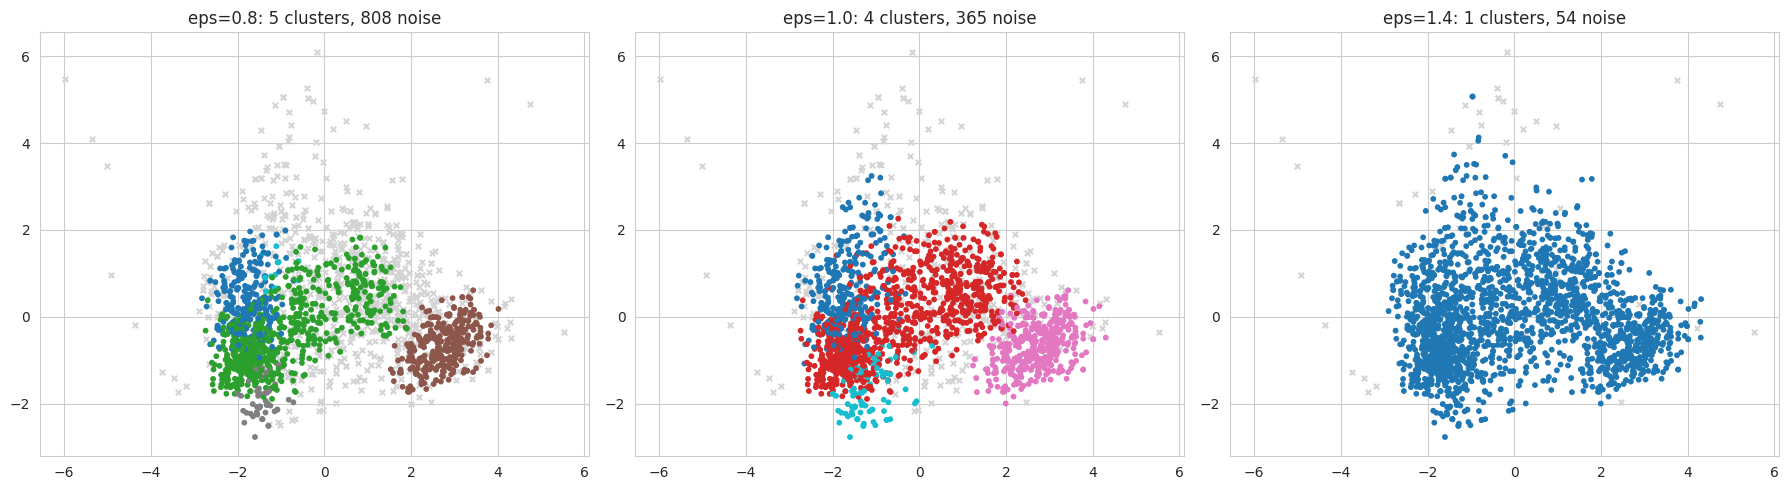

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, eps in zip(axes, [0.8, 1.0, 1.4]):
    lab = DBSCAN(eps=eps, min_samples=14).fit_predict(X_scaled)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    ax.scatter(X_2d[lab == -1, 0], X_2d[lab == -1, 1], c="lightgrey", marker="x", s=15)
    ax.scatter(X_2d[lab != -1, 0], X_2d[lab != -1, 1], c=lab[lab != -1], cmap="tab10", s=10)
    ax.set_title(f"eps={eps}: {n_cl} clusters, {(lab == -1).sum()} noise")

plt.tight_layout()
plt.show()

Same data, same min_samples, very different answers:

eps = 0.8 - 5 clusters but 808 customers (36.5%) labelled noise: too strict.

eps = 1.0 - 4 clusters, 365 noise: the balance I chose.

eps = 1.4 - just 1 cluster and 54 noise: everything has merged.

So a change of only 0.4 in eps takes us from "too fragmented" to "no segmentation at all". That is why parameter tuning is the most important step with DBSCAN.

## 13. Comparing with the Exploratory Analysis

| What EDA suggested | What DBSCAN found |
|---|---|
| Income and spending move together (r = 0.79) | Cluster 2 has both the highest income and the highest spend; clusters 0 and 3 have both the lowest |
| Children reduce spending (r = -0.50) and increase deal use (r = 0.44) | Spend falls from cluster 2 (0 kids, ~1,401) -> cluster 1 (1 kid, ~401) -> cluster 0 (2 kids, ~130); deals rise from 0.98 to 3.05 |
| Higher income means fewer web visits (r = -0.65) | Cluster 2 visits the website about 2 times a month, other clusters about 6 |
| Past campaign acceptance links with response (r = 0.43) | Cluster 2 has the most past acceptances (0.71) and the highest response (28.8%) |
| The deal-purchase and income boxplots showed extreme values | Those customers ended up as noise instead of distorting a cluster |

The clusters agree with the EDA, and the campaign response check (data DBSCAN never saw) shows real differences between the groups. That gives me confidence the segmentation means something.

One thing DBSCAN added that the EDA did not show clearly: customers **without** children are not one group. They split into a wealthy, high-spending segment and a much smaller, young, low-income segment.

14. Conclusion
Final model: DBSCAN with eps = 1.0 and min_samples = 14, on 7 standardised features, giving 4 clusters plus 16.5% noise (silhouette 0.172, Davies-Bouldin 1.65).

Main takeaways

Household size and income are the main things that separate customers. The four segments are affluent childless customers, one-child mainstream customers, two-children budget families, and young low-income childless customers.

Cluster 2 (18% of customers) is the most valuable group: it spends about 3.5x the one-child group and responds to campaigns about 3x as often.         

Premium products (wine, meat) and catalogue offers fit them; discounts are not needed (they make about 1 deal purchase).

Family clusters (0 and 1) are deal-driven and visit the website more. Online promotions and bundle discounts make more sense for them than premium mailings.

Cluster 3 is small and low-spending. It's probably a low priority for expensive campaigns, but could be a long-term growth group since they are the youngest.

Noise is informative: it contains the 3-children families, extreme deal hunters and a few suspicious records. It should be reviewed, not deleted.
Limitations (honest view)

The silhouette score is modest. The data forms one continuous cloud, so the borders between segments are soft.

Because Children is a whole number, it strongly shapes the density. A different feature choice (e.g. without Children) would give different groups.

DBSCAN uses one eps for the whole dataset, so it struggles when some segments are naturally denser than others. HDBSCAN (which handles varying density) would be a sensible next step.

PCA plots only show 68% of the variation, so clusters that look overlapping in 2D can still be separate in 7D.